# Part 3: Presentation Visualizations
Run these cells to generate beautiful, presentation-ready visualizations for the BTP Viva.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set a clean, presentation-ready style
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams['figure.figsize'] = (10, 6)

### 1. Radar/Spider Chart of 4D Features
This proves why a multi-dimensional approach is necessary. We mock the standardized features of different clients.

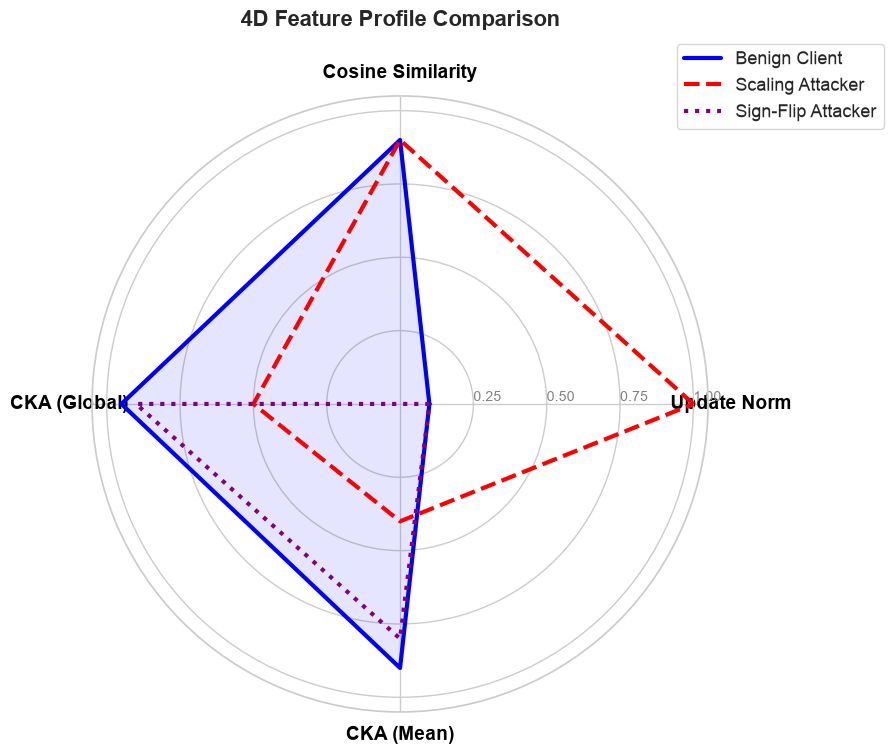

In [2]:
from math import pi

def plot_radar():
    # Categories: Norm, Cosine, CKA_Global, CKA_Mean
    categories = ['Update Norm', 'Cosine Similarity', 'CKA (Global)', 'CKA (Mean)']
    N = len(categories)
    
    # Mock standardized feature values
    benign = [0.1, 0.9, 0.95, 0.9]
    scaling_attacker = [1.0, 0.9, 0.5, 0.4]    # Huge norm
    signflip_attacker = [0.1, 0.0, 0.9, 0.8]   # Shifted cosine to [0,1] for radar
    
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    # Draw axes
    plt.xticks(angles[:-1], categories, color='black', size=14, weight='bold')
    ax.set_rlabel_position(0)
    plt.yticks([0.25, 0.5, 0.75, 1.0], ["0.25","0.50","0.75","1.00"], color="grey", size=10)
    plt.ylim(0, 1.05)
    
    # Plot Benign
    val_benign = benign + benign[:1]
    ax.plot(angles, val_benign, linewidth=3, linestyle='solid', label='Benign Client', color='blue')
    ax.fill(angles, val_benign, 'blue', alpha=0.1)
    
    # Plot Scaling Attacker
    val_scaling = scaling_attacker + scaling_attacker[:1]
    ax.plot(angles, val_scaling, linewidth=3, linestyle='dashed', label='Scaling Attacker', color='red')
    
    # Plot Sign-Flip Attacker
    val_signflip = signflip_attacker + signflip_attacker[:1]
    ax.plot(angles, val_signflip, linewidth=3, linestyle='dotted', label='Sign-Flip Attacker', color='purple')
    
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.title('4D Feature Profile Comparison', size=16, weight='bold', y=1.1)
    plt.show()

plot_radar()

### 2. Suspicion Score Bar Chart
This shows how our formula mathematically identifies the correct cluster.

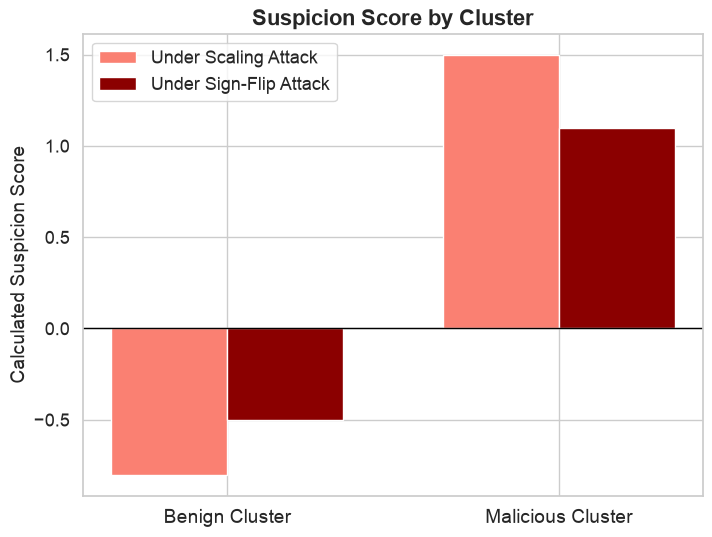

In [3]:
def plot_suspicion():
    labels = ['Benign Cluster', 'Malicious Cluster']
    scores_scaling = [-0.8, 1.5]
    scores_signflip = [-0.5, 1.1]
    
    x = np.arange(len(labels))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(8, 6))
    rects1 = ax.bar(x - width/2, scores_scaling, width, label='Under Scaling Attack', color='salmon')
    rects2 = ax.bar(x + width/2, scores_signflip, width, label='Under Sign-Flip Attack', color='darkred')
    
    ax.set_ylabel('Calculated Suspicion Score', fontsize=14)
    ax.set_title('Suspicion Score by Cluster', fontsize=16, weight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=14)
    ax.legend()
    
    # Add a horizontal line at 0 for reference
    ax.axhline(0, color='black', linewidth=1)
    plt.show()

plot_suspicion()

### 3. Non-IID Data Distribution Heatmap
Visualizes Dirichlet Partitioning (Alpha=0.5). Proves why naive filtering fails (benign clients are highly non-IID).

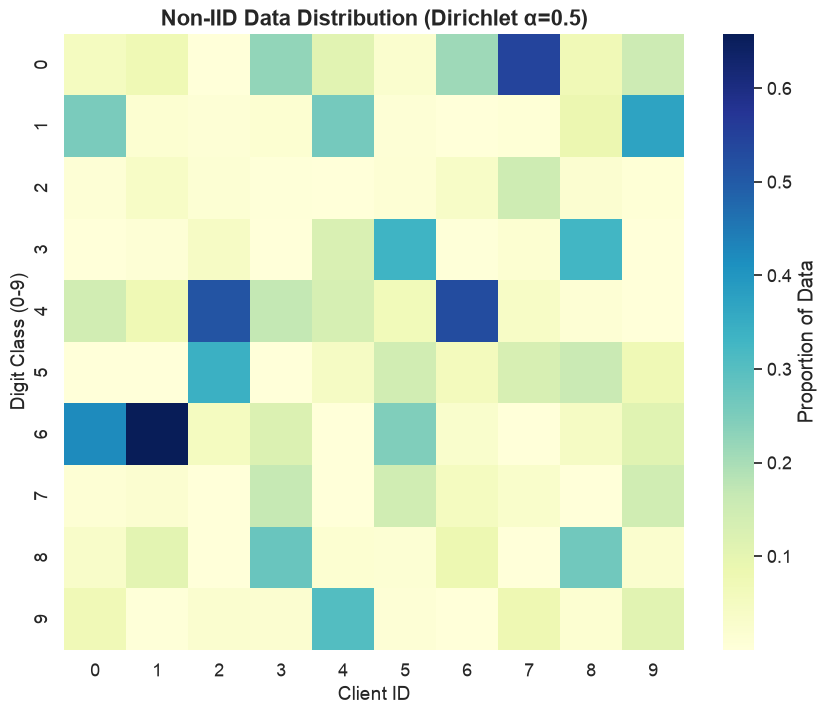

In [4]:
def plot_noniid_heatmap():
    # Mock data distribution for 10 clients and 10 classes
    np.random.seed(42)
    # Generate Dirichlet distribution for each class
    distribution = np.random.dirichlet(np.ones(10) * 0.5, size=10).T
    # Normalize by client to get proportions
    distribution = distribution / distribution.sum(axis=0)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(distribution, annot=False, cmap='YlGnBu', cbar_kws={'label': 'Proportion of Data'})
    plt.title('Non-IID Data Distribution (Dirichlet α=0.5)', fontsize=16, weight='bold')
    plt.xlabel('Client ID', fontsize=14)
    plt.ylabel('Digit Class (0-9)', fontsize=14)
    plt.show()

plot_noniid_heatmap()